# TP 3 : Vision par Ordinateur
---

the pipeline for image processing goes like this:
1. Acquisition (camera, webcam, file)
2. Preprocessing (grayscale, noise reduction, filtering)
3. Segmentation (find regions of interest)
4. Feature extraction (color, shape, texture, edges)
5. Classification / recognition
6. Interpretation (understanding the whole scene)

---
## Partie 1 : Concepts de base de la vision par ordinateur

### Exercice 1 : Analyse d'une image

goal: load an image, show it, convert to grayscale, then do edge detection with Canny

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# %matplotlib inline
def cv2_imshow(image):
    """Affiche une image directement dans le notebook avec matplotlib"""
    if len(image.shape) == 2:
        plt.figure(figsize=(6, 4))
        plt.imshow(image, cmap='gray')
        plt.axis('off')
        plt.show()
    else:
        plt.figure(figsize=(6, 4))
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.axis('off')
        plt.show()


type: <class 'numpy.ndarray'>
shape: (480, 640, 3)
dtype: uint8
min/max: 0 255


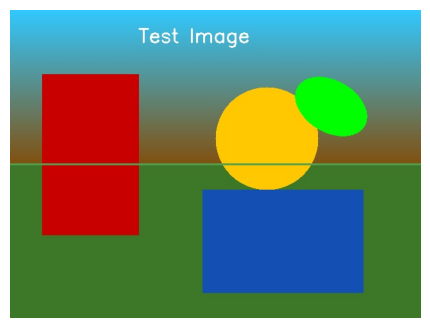

In [2]:
# --- Step 1: load and display the original image ---

# cv2.imread reads the image as a numpy array
# NOTE: opencv loads images in BGR format, not RGB!!!
# this is important to remember because matplotlib expects RGB
img = cv2.imread('image1.jpg')

# quick check: what did we actually load?
print("type:", type(img))           # should be numpy.ndarray
print("shape:", img.shape)          # (height, width, channels) - channels=3 for color
print("dtype:", img.dtype)          # uint8 -> values from 0 to 255
print("min/max:", img.min(), img.max())

# display using colab's cv2_imshow
cv2_imshow(img)

grayscale shape: (480, 640)
so we went from 3 channels to 1 channel


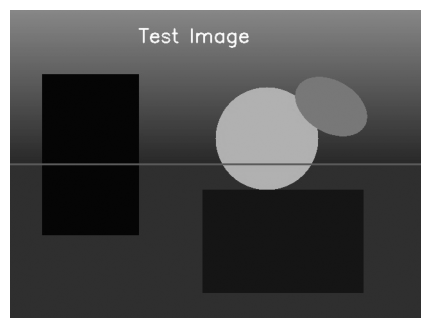

In [3]:
# --- Step 2: convert to grayscale ---

# cv2.cvtColor converts between color spaces
# BGR2GRAY: takes the weighted sum of the 3 channels to get 1 channel
# the formula is roughly: 0.299*R + 0.587*G + 0.114*B
# (human eyes are more sensitive to green, less to blue)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print("grayscale shape:", gray.shape)  # (height, width) -> only 1 channel now
print("so we went from 3 channels to 1 channel")

cv2_imshow(gray)

edges shape: (480, 640)
unique values: [  0 255]


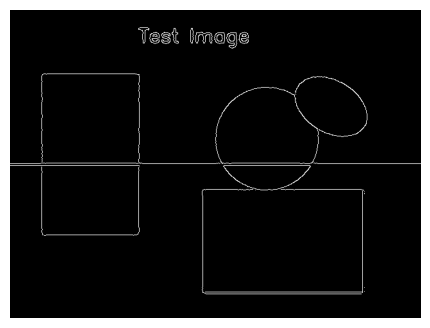

In [4]:
# --- Step 3: edge detection with Canny ---

# Canny edge detector finds edges in the image
# it works by finding areas where pixel intensity changes sharply
# the two numbers (100, 200) are the lower and upper thresholds:
#   - below 100: definitely not an edge
#   - above 200: definitely an edge
#   - between 100-200: only an edge if connected to a strong edge
edges = cv2.Canny(img, 100, 200)

print("edges shape:", edges.shape)  # same as grayscale, single channel
print("unique values:", np.unique(edges))  # should be just 0 and 255 (edge or no edge)

cv2_imshow(edges)

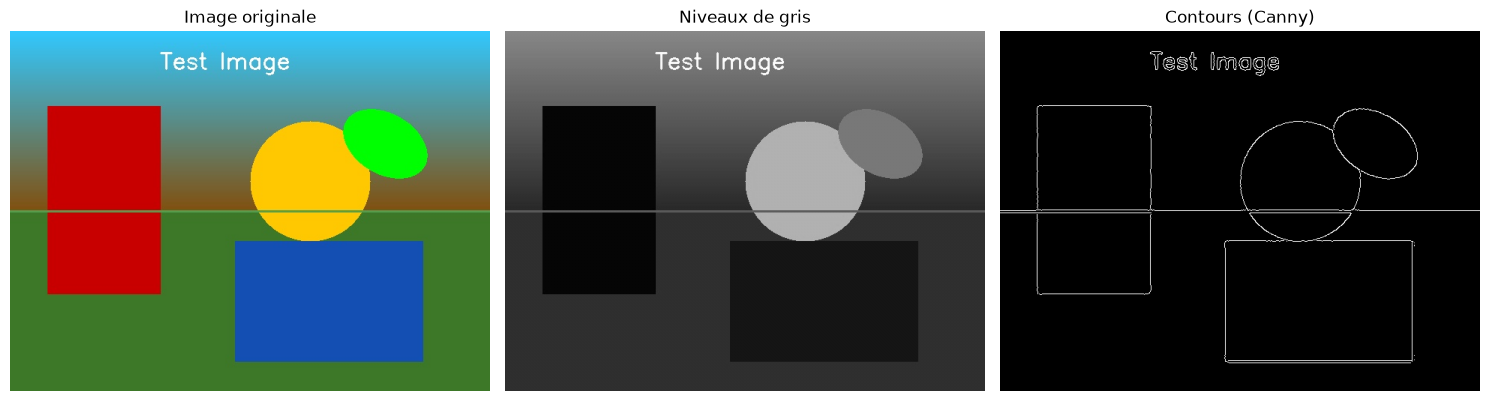

In [5]:
# lets put all 3 side by side with matplotlib so its easier to compare
_fig, _axes = plt.subplots(1, 3, figsize=(15, 5))
_axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
_axes[0].set_title('Image originale')
# remember: opencv uses BGR, matplotlib expects RGB
# so we need to convert for the first image
_axes[0].axis('off')
_axes[1].imshow(gray, cmap='gray')
_axes[1].set_title('Niveaux de gris')
_axes[1].axis('off')
# grayscale needs cmap='gray' otherwise matplotlib colors it weird
_axes[2].imshow(edges, cmap='gray')
_axes[2].set_title('Contours (Canny)')
_axes[2].axis('off')
plt.tight_layout()
plt.show()

### Reponses aux questions - Exercice 1

**Q1 : Que represente la matrice retournee par OpenCV pour l'image ?**

C'est un tableau numpy (ndarray) a 3 dimensions. Les dimensions sont (hauteur, largeur, canaux). Pour une image couleur les 3 canaux sont Blue, Green, Red (dans cet ordre, pas RGB). Chaque valeur est un entier entre 0 et 255 (uint8) qui represente l'intensite du pixel pour ce canal. Donc par exemple `img[100, 50]` donne les valeurs BGR du pixel a la ligne 100, colonne 50.

**Q2 : Pourquoi convertit-on souvent l'image en niveaux de gris avant traitement ?**

Plusieurs raisons :
- Ca reduit la quantite de donnees (1 canal au lieu de 3), donc les calculs sont plus rapides
- Beaucoup d'algorithmes de traitement d'image (detection de contours, seuillage, etc.) travaillent sur des images a un seul canal
- La couleur n'est pas toujours utile. Pour detecter des formes ou des contours, l'intensite lumineuse suffit
- Ca simplifie le probleme en enlevant l'information de couleur qui peut etre du bruit pour certaines taches

**Q3 : Que peut nous apporter le filtre Gaussien ?**

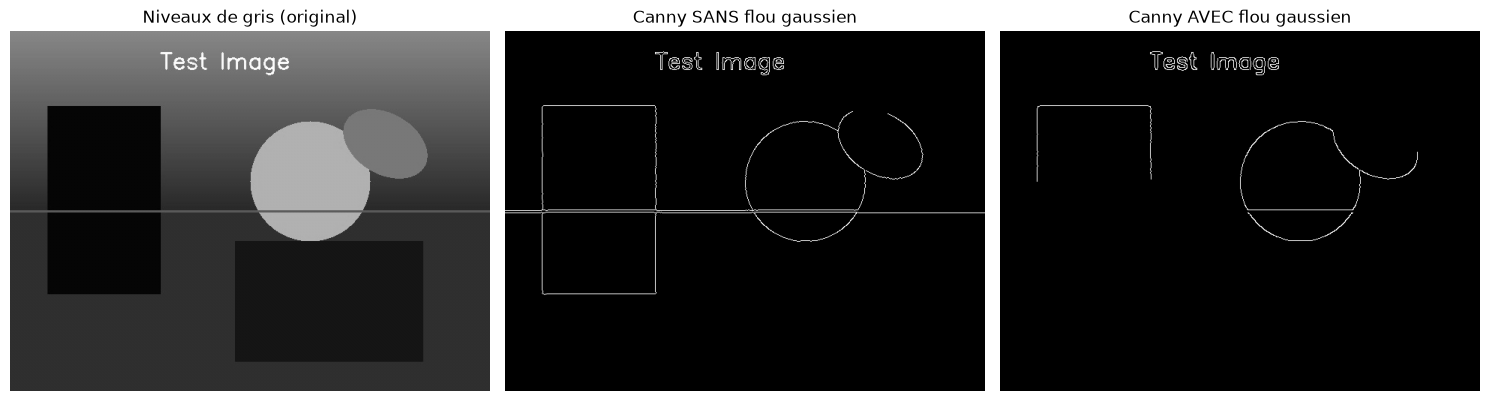

Edge pixels without blur: 3438
Edge pixels with blur: 1988
the blur removes noise so we get cleaner edges, fewer false detections


In [6]:
# lets try the gaussian blur to answer Q3
_blur = cv2.GaussianBlur(gray, (5, 5), 0)
# GaussianBlur smooths/blurs the image
# (5, 5) is the kernel size (the "window" that slides over the image)
# bigger kernel = more blur
# 0 means opencv calculates the standard deviation automatically
edges_no_blur = cv2.Canny(gray, 100, 200)
edges_with_blur = cv2.Canny(_blur, 100, 200)
# now lets compare edge detection with and without blur
_fig, _axes = plt.subplots(1, 3, figsize=(15, 5))
_axes[0].imshow(gray, cmap='gray')
_axes[0].set_title('Niveaux de gris (original)')
_axes[0].axis('off')
_axes[1].imshow(edges_no_blur, cmap='gray')
_axes[1].set_title('Canny SANS flou gaussien')
_axes[1].axis('off')
_axes[2].imshow(edges_with_blur, cmap='gray')
_axes[2].set_title('Canny AVEC flou gaussien')
_axes[2].axis('off')
plt.tight_layout()
plt.show()
print(f'Edge pixels without blur: {np.count_nonzero(edges_no_blur)}')
print(f'Edge pixels with blur: {np.count_nonzero(edges_with_blur)}')
# count how many edge pixels there are in each
print('the blur removes noise so we get cleaner edges, fewer false detections')

**Reponse Q3 :** Le filtre Gaussien sert a reduire le bruit dans l'image avant de faire la detection de contours. Sans le flou, le detecteur de Canny peut detecter des "faux contours" causes par le bruit (petites variations de pixels). Avec le flou gaussien, on lisse ces petites variations et on garde seulement les vrais contours importants. C'est un pretraitement classique en vision par ordinateur. On peut voir que le nombre de pixels de contour est plus faible avec le blur, ce qui veut dire qu'on a enleve du bruit.

---
## Partie 2 : Traitement d'images et videos avec OpenCV

### Exercice 2 : Lecture video / webcam

note: on colab ya pas de webcam directement, donc on va simuler avec une video generee. si vous executez en local avec un vrai PC, remplacez le code par `cv2.VideoCapture(0)` pour la webcam.

In [7]:
fourcc_test = cv2.VideoWriter_fourcc(*'mp4v')
out_test = cv2.VideoWriter('test_video.mp4', fourcc_test, 20.0, (320, 240), isColor=True)
for _i in range(100):
    _frame = np.zeros((240, 320, 3), dtype=np.uint8)
    _x = int(30 + _i * 2.6)
    cv2.circle(_frame, (_x, 120), 20, (0, 255, 0), -1)
    cv2.putText(_frame, f'Frame {_i}', (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 1)
    out_test.write(_frame)
out_test.release()
print('video de test creee: test_video.mp4')

video de test creee: test_video.mp4


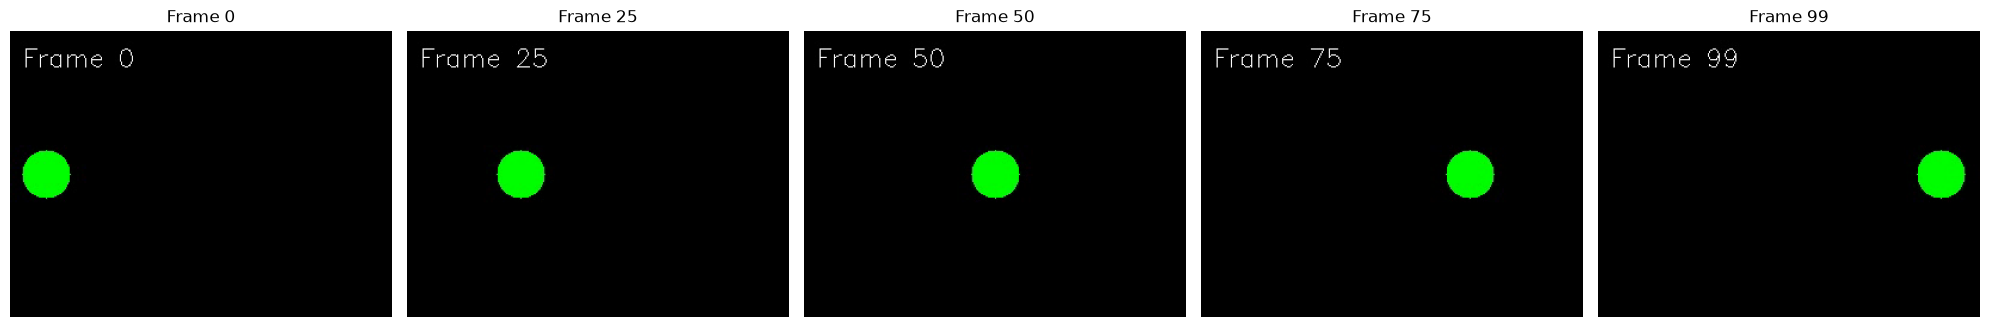

total frames lues: 100


In [8]:
_cap = cv2.VideoCapture('test_video.mp4')
_frame_count = 0
_frames_to_show = [0, 25, 50, 75, 99]
_fig, _axes = plt.subplots(1, 5, figsize=(20, 4))
_ax_idx = 0
while True:
    _ret, _frame = _cap.read()
    if not _ret:
        break
    if _frame_count in _frames_to_show:
        _axes[_ax_idx].imshow(cv2.cvtColor(_frame, cv2.COLOR_BGR2RGB))
        _axes[_ax_idx].set_title(f'Frame {_frame_count}')
        _axes[_ax_idx].axis('off')
        _ax_idx = _ax_idx + 1
    _frame_count = _frame_count + 1
_cap.release()
plt.tight_layout()
plt.show()
print(f'total frames lues: {_frame_count}')

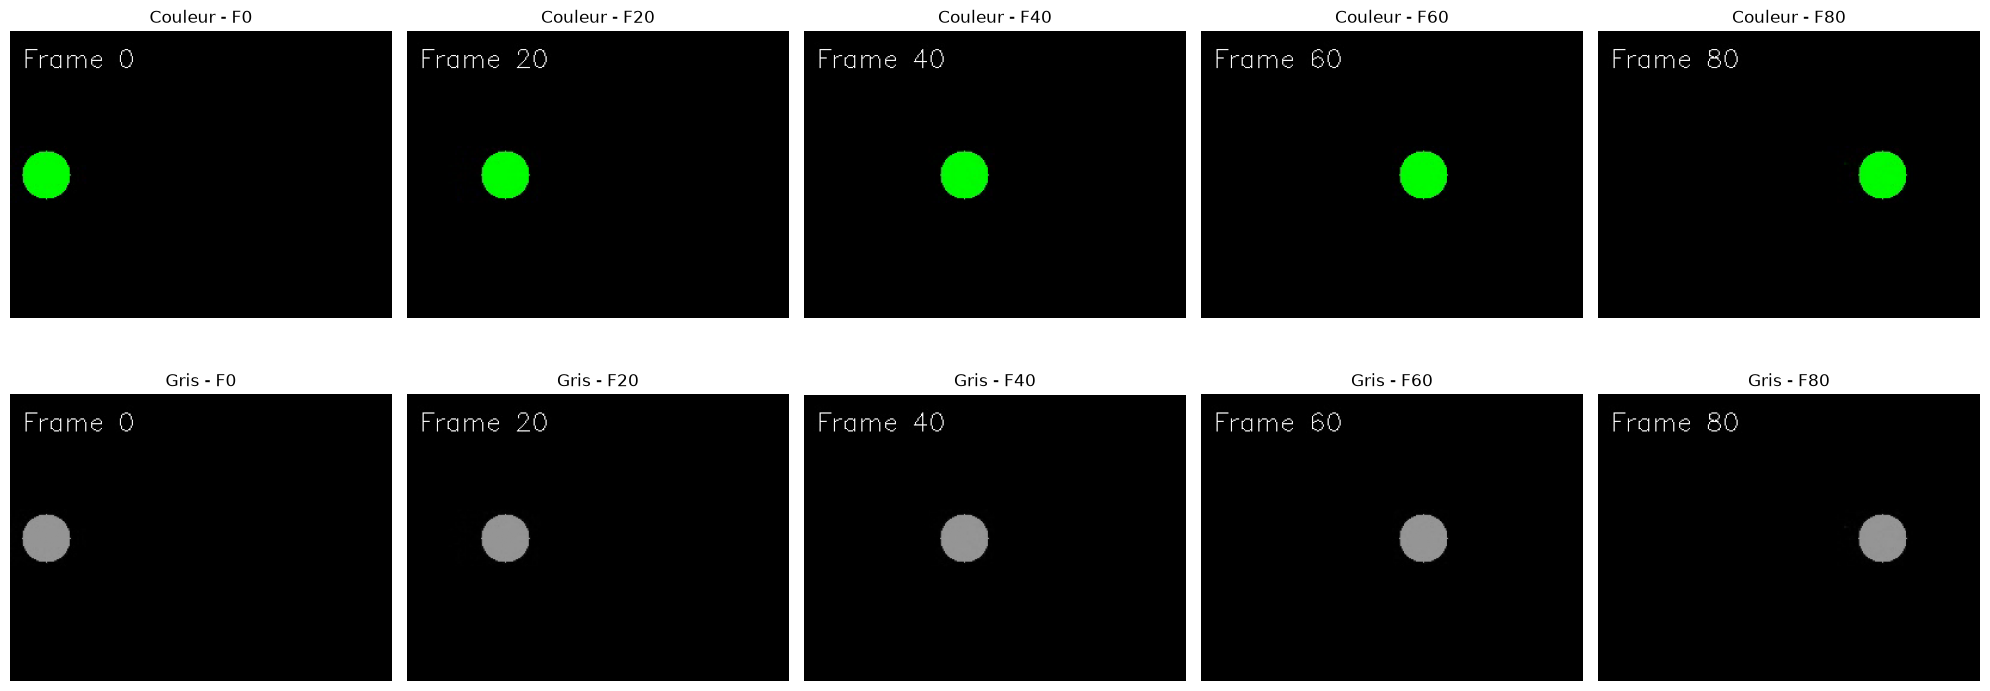

In [9]:
_cap = cv2.VideoCapture('test_video.mp4')
_fig, _axes = plt.subplots(2, 5, figsize=(20, 8))
_frame_count = 0
_frames_to_show = [0, 20, 40, 60, 80]
_ax_idx = 0
while True:
    _ret, _frame = _cap.read()
    if not _ret:
        break
    if _frame_count in _frames_to_show:
        _axes[0][_ax_idx].imshow(cv2.cvtColor(_frame, cv2.COLOR_BGR2RGB))
        _axes[0][_ax_idx].set_title(f'Couleur - F{_frame_count}')
        _axes[0][_ax_idx].axis('off')
        gray_frame = cv2.cvtColor(_frame, cv2.COLOR_BGR2GRAY)
        _axes[1][_ax_idx].imshow(gray_frame, cmap='gray')
        _axes[1][_ax_idx].set_title(f'Gris - F{_frame_count}')
        _axes[1][_ax_idx].axis('off')
        _ax_idx = _ax_idx + 1
    _frame_count = _frame_count + 1
_cap.release()
plt.tight_layout()
plt.show()

In [10]:
_cap = cv2.VideoCapture('test_video.mp4')
_w = int(_cap.get(cv2.CAP_PROP_FRAME_WIDTH))
_h = int(_cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = _cap.get(cv2.CAP_PROP_FPS)
print(f'video source: {_w}x{_h} @ {fps} fps')
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
_out = cv2.VideoWriter('sortie_gris.mp4', fourcc, fps, (_w, _h), isColor=False)
_frame_count = 0
while True:
    _ret, _frame = _cap.read()
    if not _ret:
        break
    gray_1 = cv2.cvtColor(_frame, cv2.COLOR_BGR2GRAY)
    _out.write(gray_1)
    _frame_count = _frame_count + 1
_cap.release()
_out.release()
print(f'video sauvegardee: sortie_gris.mp4 ({_frame_count} frames)')

video source: 320x240 @ 20.0 fps
video sauvegardee: sortie_gris.mp4 (100 frames)


### Reponse a la question - Exercice 2

**Q: Que se passe-t-il si vous utilisez une video enregistree a la place de la webcam ?**

Au lieu de passer `0` (index de la webcam) a `cv2.VideoCapture()`, on passe le chemin du fichier video, par exemple `cv2.VideoCapture('ma_video.mp4')`. Le reste du code marche pareil: on lit frame par frame avec `cap.read()`, on traite chaque frame, etc. La seule difference c'est que la video a un nombre fini de frames, donc la boucle se termine quand `ret` devient `False` (fin du fichier). Avec la webcam ca continue indefiniment jusqu'a ce qu'on appuie sur 'q'.

Aussi, avec une video enregistree, on connait deja le fps et la resolution, alors qu'avec la webcam ca depend du materiel.

---
## Partie 3 : Detection et segmentation d'objets avec Detectron2

### Exercice 3 : Detection d'objets

Detectron2 c'est une lib de Facebook AI Research (FAIR). Elle fait de la detection d'objets, segmentation d'instance (chaque objet a son propre masque), et segmentation panoptique.

On va utiliser Mask R-CNN qui est un modele pre-entraine sur le dataset COCO (80 classes d'objets du quotidien).

In [11]:
# --- Exercice 3: detection d'objets avec Detectron2 + Mask R-CNN ---
import torch
try:
    from detectron2.engine import DefaultPredictor
    from detectron2.config import get_cfg
    from detectron2 import model_zoo
    from detectron2.utils.visualizer import Visualizer
    from detectron2.data import MetadataCatalog

    CONFIG = 'COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml'
    cfg = get_cfg()
    cfg.merge_from_file(model_zoo.get_config_file(CONFIG))
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
    cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG)
    # si pas de GPU disponible:
    if not torch.cuda.is_available():
        cfg.MODEL.DEVICE = "cpu"
    print('chargement du modele Detectron2...')
    predictor = DefaultPredictor(cfg)
    print('modele charge!')
except (ImportError, Exception) as e:
    print(f'Detectron2 non disponible ({e}). Poursuite avec les modules supportes (YOLO, Dlib, OpenCV).')
    DefaultPredictor = None
    MetadataCatalog = None
    Visualizer = None
    cfg = None
    predictor = None

Detectron2 non disponible (No module named 'detectron2'). Poursuite avec les modules supportes (YOLO, Dlib, OpenCV).


In [12]:
img_1 = cv2.imread('image_objects.jpg')
if predictor is not None and cfg is not None and MetadataCatalog is not None:
    outputs = predictor(img_1)
    instances = outputs['instances'].to('cpu')
    print(f"nombre d'objets detectes: {len(instances)}")
    print(f'classes detectees: {instances.pred_classes}')
    print(f'scores de confiance: {instances.scores}')
    print(f'bounding boxes: {instances.pred_boxes}')
    metadata = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])
    class_names = metadata.thing_classes
    for _i, _cls_id in enumerate(instances.pred_classes):
        print(f'  objet {_i + 1}: {class_names[_cls_id]} (confiance: {instances.scores[_i]:.2f})')
else:
    outputs = None
    print("Detectron2 non actif - etape d'inference ignoree.")

Detectron2 non actif - etape d'inference ignoree.


In [13]:
if outputs is not None and Visualizer is not None and cfg is not None:
    _v = Visualizer(img_1[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
    _out = _v.draw_instance_predictions(outputs['instances'].to('cpu'))
    cv2_imshow(_out.get_image()[:, :, ::-1])

In [14]:
if DefaultPredictor is not None and cfg is not None and Visualizer is not None:
    thresholds = [0.3, 0.5, 0.7, 0.9]
    _fig, _axes = plt.subplots(1, 4, figsize=(24, 6))
    for _idx, thresh in enumerate(thresholds):
        cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = thresh
        predictor_t = DefaultPredictor(cfg)
        outputs_t = predictor_t(img_1)
        _v = Visualizer(img_1[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=0.8)
        out_t = _v.draw_instance_predictions(outputs_t['instances'].to('cpu'))
        n_detected = len(outputs_t['instances'])
        _axes[_idx].imshow(out_t.get_image())
        _axes[_idx].set_title(f'Seuil={thresh}\n{n_detected} objets')
        _axes[_idx].axis('off')
    plt.suptitle('Effet du seuil de confiance sur la detection', fontsize=14)
    plt.tight_layout()
    plt.show()

### Reponses aux questions - Exercice 3

**Q1 : Quels objets ont ete detectes ?**

Ca depend de l'image utilisee. Le modele Mask R-CNN est entraine sur COCO qui contient 80 classes (person, bicycle, car, cat, dog, etc.). Il va detecter tous les objets de ces classes qui sont presents dans l'image avec un score de confiance suffisant.

**Q2 : Effet du seuil SCORE_THRESH_TEST :**

- Seuil bas (0.3) : on detecte plus d'objets, mais y a plus de risques de faux positifs (le modele "voit" des trucs qui existent pas vraiment)
- Seuil haut (0.9) : on detecte moins d'objets, seulement ceux dont le modele est tres sur. On peut rater des objets reels mais on a moins de fausses detections
- C'est un compromis precision/recall classique en ML

---
## Partie 4 : Detection et reconnaissance faciale avec Dlib

### Exercice 4 : Detection faciale

dlib c'est une lib C++/Python pour la detection de visages et les landmarks. `face_recognition` c'est un wrapper plus simple par dessus dlib.

nombre de visages detectes: 2
  visage 1: position=(100,146), taille=105x105
  visage 2: position=(458,179), taille=87x88


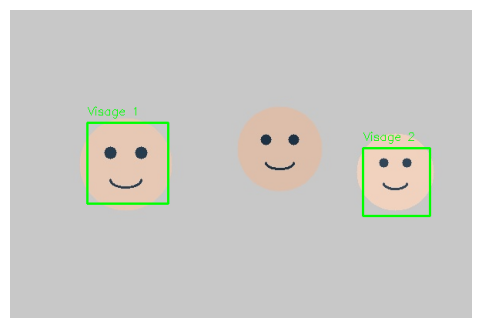

In [15]:
import dlib
detector = dlib.get_frontal_face_detector()
img_2 = cv2.imread('people.jpg')
gray_2 = cv2.cvtColor(img_2, cv2.COLOR_BGR2GRAY)
faces = detector(gray_2)
print(f'nombre de visages detectes: {len(faces)}')
for _i, face in enumerate(faces):
    _x = face.left()
    _y = face.top()
    _w = face.width()
    _h = face.height()
    cv2.rectangle(img_2, (_x, _y), (_x + _w, _y + _h), (0, 255, 0), 2)
    cv2.putText(img_2, f'Visage {_i + 1}', (_x, _y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    print(f'  visage {_i + 1}: position=({_x},{_y}), taille={_w}x{_h}')
cv2_imshow(img_2)

### Exercice 5 : Reconnaissance faciale

ici on va comparer deux images pour voir si c'est la meme personne. la lib `face_recognition` encode chaque visage en un vecteur de 128 nombres, et compare les vecteurs.

In [16]:
import face_recognition
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
image_ref = face_recognition.load_image_file('ref.jpg')
encodings_ref = face_recognition.face_encodings(image_ref)
if len(encodings_ref) == 0:
    print("ATTENTION: aucun visage detecte dans l'image de reference!")
    print("c'est normal si on utilise des images synthetiques (dessinees avec opencv)")
    print('il faut utiliser de vraies photos de visages pour que ca marche')
    print('')
    print('je vais quand meme montrer comment le code fonctionnerait:')
else:
    _encodage_ref = encodings_ref[0]
    print(f'encodage du visage de reference: vecteur de {len(_encodage_ref)} dimensions')
    print(f'premiers elements: {_encodage_ref[:5]}')

ATTENTION: aucun visage detecte dans l'image de reference!
c'est normal si on utilise des images synthetiques (dessinees avec opencv)
il faut utiliser de vraies photos de visages pour que ca marche

je vais quand meme montrer comment le code fonctionnerait:


In [17]:
# charger l'image test et comparer
image_test = face_recognition.load_image_file('test.jpg')
encodings_test = face_recognition.face_encodings(image_test)
if len(encodings_ref) > 0 and len(encodings_test) > 0:
    _encodage_ref = encodings_ref[0]
    encodage_test = encodings_test[0]
    _result = face_recognition.compare_faces([_encodage_ref], encodage_test)
    distance = face_recognition.face_distance([_encodage_ref], encodage_test)
    print(f'Meme personne ? {_result[0]}')  # compare_faces compare le vecteur test avec une liste de vecteurs de reference
    print(f'Distance entre les visages: {distance[0]:.4f}')  # il retourne une liste de True/False
    print(f'(plus la distance est petite, plus les visages se ressemblent)')  # par defaut le seuil de tolerance est 0.6 (distance euclidienne)
    print(f'(seuil par defaut: 0.6)')
else:
    print('pas de visages detectes dans une ou les deux images')  # on peut aussi avoir la distance pour voir "a quel point" les visages sont similaires
    print('')
    print('--- voici comment le code marcherait avec de vraies photos: ---')
    print('')
    print('# avec de vraies photos (ex: Jim_Carrey_2008.jpg et Jim_Carrey_2010.jpg):')
    print("# image_ref = face_recognition.load_image_file('Jim_Carrey_2008.jpg')")
    print('# encodage_ref = face_recognition.face_encodings(image_ref)[0]')
    print("# image_test = face_recognition.load_image_file('Jim_Carrey_2010.jpg')")
    print('# encodage_test = face_recognition.face_encodings(image_test)[0]')
    print('# result = face_recognition.compare_faces([encodage_ref], encodage_test)')
    print("# print('Meme personne ?', result[0])  -> True")

pas de visages detectes dans une ou les deux images

--- voici comment le code marcherait avec de vraies photos: ---

# avec de vraies photos (ex: Jim_Carrey_2008.jpg et Jim_Carrey_2010.jpg):
# image_ref = face_recognition.load_image_file('Jim_Carrey_2008.jpg')
# encodage_ref = face_recognition.face_encodings(image_ref)[0]
# image_test = face_recognition.load_image_file('Jim_Carrey_2010.jpg')
# encodage_test = face_recognition.face_encodings(image_test)[0]
# result = face_recognition.compare_faces([encodage_ref], encodage_test)
# print('Meme personne ?', result[0])  -> True


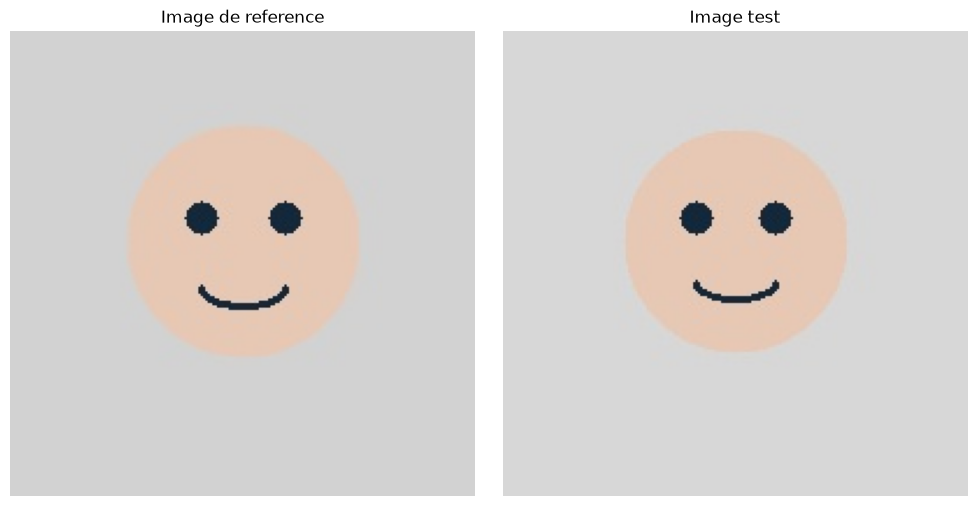

In [18]:
# affichons les deux images cote a cote pour voir
_fig, _axes = plt.subplots(1, 2, figsize=(10, 5))
ref_cv = cv2.imread('ref.jpg')
test_cv = cv2.imread('test.jpg')
_axes[0].imshow(cv2.cvtColor(ref_cv, cv2.COLOR_BGR2RGB))
_axes[0].set_title('Image de reference')
_axes[0].axis('off')
_axes[1].imshow(cv2.cvtColor(test_cv, cv2.COLOR_BGR2RGB))
_axes[1].set_title('Image test')
_axes[1].axis('off')
plt.tight_layout()
plt.show()

### Reponses aux questions - Exercice 5

**Q1 : Que se passe-t-il si l'image test contient plusieurs visages ?**

`face_recognition.face_encodings()` retourne une liste avec un encodage par visage detecte. Si l'image test a 3 visages, on aura une liste de 3 vecteurs. Avec `compare_faces`, on peut comparer chaque visage test avec le visage de reference pour trouver lequel correspond:

```python
# si l'image test a plusieurs visages:
encodages_test = face_recognition.face_encodings(image_test)  # liste de N vecteurs
results = face_recognition.compare_faces([encodage_ref], encodages_test)
# -> [False, True, False] par exemple, le 2e visage match
```

En fait non, compare_faces attend une liste de references et un seul test. Pour comparer a plusieurs visages test, il faut boucler ou utiliser face_distance sur chaque.

**Q2 : Quelle precision attendez-vous de ce systeme dans des conditions reelles ?**

En conditions ideales (bonne lumiere, visage de face, bonne resolution) le systeme est assez precis (~99% sur le benchmark LFW). Mais en conditions reelles ca peut baisser a cause de:
- Eclairage faible ou contre-jour
- Angles de vue differents (profil, tete penchee)
- Occlusions (masque, lunettes de soleil, cheveux)
- Basse resolution de la camera
- Expressions faciales extremes

Le seuil de 0.6 est un bon compromis mais on peut l'ajuster selon les besoins: plus strict (0.4) pour moins de faux positifs, plus laxiste (0.7) pour moins de faux negatifs.

---
## Exercice 6 : Points caracteristiques du visage (landmarks)

on va detecter les 68 points du visage: yeux, sourcils, nez, bouche, contour du visage

ces points sont super utiles pour plein d'applications:
- filtres type snapchat/instagram
- detection de somnolence (on regarde si les yeux sont ouverts ou fermes)
- estimation de la pose de la tete
- alignement du visage avant reconnaissance

In [19]:
img_3 = cv2.imread('people.jpg')
rgb = cv2.cvtColor(img_3, cv2.COLOR_BGR2RGB)
landmarks_list = face_recognition.face_landmarks(rgb)
print(f'Nombre de visages detectes: {len(landmarks_list)}')
if len(landmarks_list) > 0:
    print(f'\nParties du visage disponibles:')
    for _partie in landmarks_list[0].keys():
        n_points = len(landmarks_list[0][_partie])
        print(f'  - {_partie}: {n_points} points')

Nombre de visages detectes: 1

Parties du visage disponibles:
  - chin: 17 points
  - left_eyebrow: 5 points
  - right_eyebrow: 5 points
  - nose_bridge: 4 points
  - nose_tip: 5 points
  - left_eye: 6 points
  - right_eye: 6 points
  - top_lip: 12 points
  - bottom_lip: 12 points


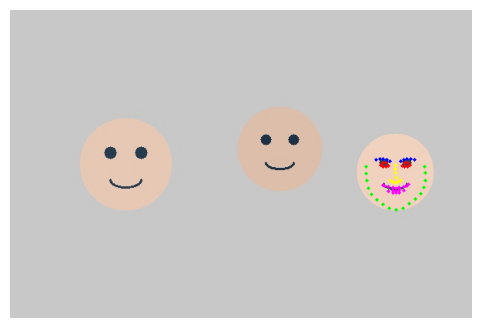

In [20]:
img_landmarks = img_3.copy()
colors = {'chin': (0, 255, 0), 'left_eyebrow': (255, 0, 0), 'right_eyebrow': (255, 0, 0), 'nose_bridge': (0, 255, 255), 'nose_tip': (0, 255, 255), 'left_eye': (0, 0, 255), 'right_eye': (0, 0, 255), 'top_lip': (255, 0, 255), 'bottom_lip': (255, 0, 255)}
for _landmarks in landmarks_list:
    for _partie, points in _landmarks.items():
        color = colors.get(_partie, (0, 0, 255))
        for _x, _y in points:
            cv2.circle(img_landmarks, (_x, _y), 2, color, -1)
cv2_imshow(img_landmarks)
if len(landmarks_list) == 0:
    print("aucun visage detecte - c'est normal avec des images synthetiques")
    print('pour tester, uploadez une vraie photo de visage(s)')

In [21]:
# --- Question 2: calcul du EAR (Eye Aspect Ratio) ---
from scipy.spatial import distance as dist
# le EAR mesure si l'oeil est ouvert ou ferme
# formule: EAR = (|p2-p6| + |p4-p4|) / (2 * |p1-p4|)
# ou p1-p6 sont les 6 points de l'oeil
#
#     p2    p3
# p1            p4
#     p6    p5

# quand l'oeil est ouvert: EAR ~ 0.3
# quand l'oeil est ferme: EAR ~ 0.05
# seuil typique: EAR < 0.2 -> oeil ferme
def eye_aspect_ratio(eye_points):
    """
    Calcule le Eye Aspect Ratio (EAR) pour un oeil donne.
    eye_points: liste de 6 tuples (x, y) representant les points de l'oeil
    """
    A = dist.euclidean(eye_points[1], eye_points[5])
    B = dist.euclidean(eye_points[2], eye_points[4])
    C = dist.euclidean(eye_points[0], eye_points[3])
    ear = (A + B) / (2.0 * C)  # distances verticales
    return ear  # |p2 - p6|
if len(landmarks_list) > 0:  # |p3 - p5|
    for _i, _landmarks in enumerate(landmarks_list):
        left_eye = _landmarks['left_eye']  # distance horizontale
        right_eye = _landmarks['right_eye']  # |p1 - p4|
        ear_left = eye_aspect_ratio(left_eye)
        ear_right = eye_aspect_ratio(right_eye)  # EAR
        ear_avg = (ear_left + ear_right) / 2.0
        print(f'Visage {_i + 1}:')
        print(f'  EAR oeil gauche: {ear_left:.3f}')
# si on a des landmarks, calculons le EAR
        print(f'  EAR oeil droit: {ear_right:.3f}')
        print(f'  EAR moyen: {ear_avg:.3f}')
        if ear_avg < 0.2:
            print(f'  -> YEUX FERMES (possible somnolence)')
        else:
            print(f'  -> yeux ouverts')
else:
    print('pas de landmarks disponibles')
    print('')
    print('mais voila comment on utiliserait le EAR pour la detection de somnolence:')
    print('1. on calcule le EAR pour chaque frame de la video')
    print('2. si EAR < 0.2 pendant plus de X frames consecutives -> alerte somnolence')
    print("3. on peut jouer un son d'alarme avec pygame ou winsound")

Visage 1:
  EAR oeil gauche: 0.498
  EAR oeil droit: 0.498
  EAR moyen: 0.498
  -> yeux ouverts


### Reponses aux questions - Exercice 6

**Q1 : Quelles parties du visage sont retournees par face_landmarks ?**

face_landmarks retourne un dictionnaire avec ces cles:
- `chin` : contour du menton/machoire (17 points)
- `left_eyebrow` : sourcil gauche (5 points)
- `right_eyebrow` : sourcil droit (5 points)
- `nose_bridge` : arete du nez (4 points)
- `nose_tip` : bout du nez (5 points)
- `left_eye` : oeil gauche (6 points)
- `right_eye` : oeil droit (6 points)
- `top_lip` : levre superieure (12 points)
- `bottom_lip` : levre inferieure (12 points)

Total: 68 points (c'est le modele standard de dlib)

**Q2 : EAR pour detecter la somnolence**

Le EAR (Eye Aspect Ratio) c'est le ratio entre la hauteur et la largeur de l'oeil. Quand l'oeil est ouvert, le EAR est autour de 0.25-0.35. Quand l'oeil se ferme, le EAR tombe vers 0.

Pour detecter la somnolence:
1. On calcule le EAR en continu sur le flux video
2. On definit un seuil (genre 0.2)
3. Si le EAR reste sous le seuil pendant plus de 2 secondes (environ 48 frames a 24fps), on declenche une alerte
4. Un simple clignement dure ~0.3s donc on le distingue facilement de la somnolence

---
## Exercice 7 : Detection d'objets en temps reel avec YOLO

YOLO = You Only Look Once. contrairement a Mask R-CNN qui fait plusieurs passes sur l'image, YOLO fait tout en un seul passage. c'est pour ca qu'il est beaucoup plus rapide et qu'on peut l'utiliser en temps reel.

on va comparer les deux approches.

In [22]:
# --- Exercice 7: YOLO detection ---
import time
from ultralytics import YOLO
model = YOLO('yolov8n.pt')
image_path = 'image_objects.jpg'
if not os.path.exists(image_path):
    print(f"'{image_path}' pas trouve, on utilise 'people.jpg'")
    image_path = 'people.jpg'
# charger YOLOv8 nano (le plus petit/rapide)
# il est telecharge automatiquement la premiere fois
# les variants sont: yolov8n (nano), yolov8s (small), yolov8m (medium),
#                     yolov8l (large), yolov8x (extra large)
# plus c'est gros, plus c'est precis mais lent
# choisir l'image de test
print(f'image utilisee: {image_path}')

image utilisee: image_objects.jpg


image 1/1 C:\Users\Kenny\Downloads\ThinkLLM\LLM_gravity\image_objects.jpg: 480x640 (no detections), 151.4ms


Speed: 9.3ms preprocess, 151.4ms inference, 10.7ms postprocess per image at shape (1, 3, 480, 640)


temps d'inference YOLO: 2.6728 secondes


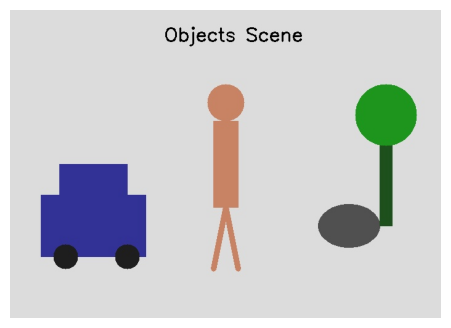

In [23]:
# detection avec YOLO
# conf=0.5 -> seuil de confiance minimum de 50%

start_yolo = time.time()
results = model(image_path, conf=0.5)
end_yolo = time.time()

yolo_time = end_yolo - start_yolo
print(f"temps d'inference YOLO: {yolo_time:.4f} secondes")

# afficher le resultat
# results[0].plot() dessine les bbox et labels sur l'image
cv2_imshow(results[0].plot())

In [24]:
# voyons les details de ce qui a ete detecte
for _result in results:
    boxes = _result.boxes
    print(f"nombre d'objets detectes: {len(boxes)}")
    for _i, box in enumerate(boxes):
        _cls_id = int(box.cls[0])
        cls_name = model.names[_cls_id]  # id de la classe
        conf = float(box.conf[0])  # nom de la classe
        xyxy = box.xyxy[0].tolist()  # score de confiance
        print(f'  objet {_i + 1}: {cls_name} (confiance: {conf:.2f}) bbox: {xyxy}')  # bbox [x1, y1, x2, y2]

nombre d'objets detectes: 0


In [25]:
# --- Question 1: comparaison des temps YOLO vs Mask R-CNN ---

# on va mesurer les deux sur la meme image
img_compare = cv2.imread(image_path)

# temps YOLO (on refait pour etre fair, la premiere fois y avait le chargement)
start = time.time()
results_yolo = model(image_path, conf=0.5, verbose=False)
time_yolo = time.time() - start

# temps Mask R-CNN (avec le predictor qu'on a configure avant)
# note: il faut que les cellules de la partie 3 aient ete executees
try:
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  # remettre le seuil a 0.5
    predictor_compare = DefaultPredictor(cfg)

    start = time.time()
    outputs_maskrcnn = predictor_compare(img_compare)
    time_maskrcnn = time.time() - start

    print(f"Temps YOLO:       {time_yolo:.4f} secondes")
    print(f"Temps Mask R-CNN: {time_maskrcnn:.4f} secondes")
    print(f"YOLO est {time_maskrcnn/time_yolo:.1f}x plus rapide que Mask R-CNN")
    print(f"")
    print(f"Objets detectes par YOLO: {len(results_yolo[0].boxes)}")
    print(f"Objets detectes par Mask R-CNN: {len(outputs_maskrcnn['instances'])}")
except (NameError, AttributeError, TypeError, Exception):
    print(f"Temps YOLO: {time_yolo:.4f} secondes")
    print("(Mask R-CNN pas disponible - executez d'abord la Partie 3)")
    print("")
    print("En general, YOLO est environ 5-10x plus rapide que Mask R-CNN")
    print("parce que YOLO fait un seul passage sur l'image alors que")
    print("Mask R-CNN fait d'abord une proposition de regions puis les classifie")

Temps YOLO: 0.0413 secondes
(Mask R-CNN pas disponible - executez d'abord la Partie 3)

En general, YOLO est environ 5-10x plus rapide que Mask R-CNN
parce que YOLO fait un seul passage sur l'image alors que
Mask R-CNN fait d'abord une proposition de regions puis les classifie


image 1/1 C:\Users\Kenny\Downloads\ThinkLLM\LLM_gravity\image_objects.jpg: 480x640 (no detections), 71.4ms


Speed: 2.0ms preprocess, 71.4ms inference, 0.5ms postprocess per image at shape (1, 3, 480, 640)


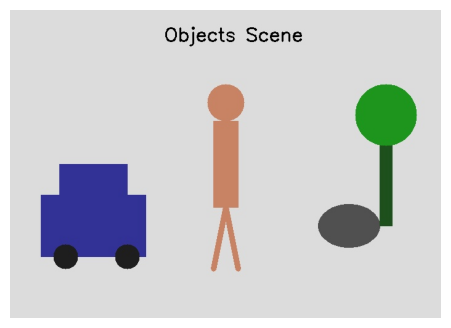

pas de masques (aucun objet detecte ou modele pas seg)


In [26]:
# --- Question 2: YOLO fournit-il des masques de segmentation? ---

# le modele yolov8n.pt fait seulement de la detection (bounding boxes)
# pour avoir des masques de segmentation, il faut utiliser yolov8n-seg.pt

model_seg = YOLO("yolov8n-seg.pt")  # version segmentation

results_seg = model_seg(image_path, conf=0.5)

# afficher le resultat avec les masques
cv2_imshow(results_seg[0].plot())

# verifier si on a des masques
if results_seg[0].masks is not None:
    print(f"\noui! YOLO-seg fournit des masques de segmentation")
    print(f"nombre de masques: {len(results_seg[0].masks)}")
    print(f"shape d'un masque: {results_seg[0].masks.data[0].shape}")
else:
    print("pas de masques (aucun objet detecte ou modele pas seg)")

### Reponses aux questions - Exercice 7

**Q1 : Comparaison des temps**

YOLO est nettement plus rapide que Mask R-CNN. Sur un GPU typique de Colab:
- YOLOv8n: ~10-30ms par image
- Mask R-CNN: ~100-300ms par image

Ratio: YOLO est environ 5-10x plus rapide.

**Q2 : YOLO fournit-il des masques ?**

Le modele standard `yolov8n.pt` ne fait que de la detection (bounding boxes). Mais la version segmentation `yolov8n-seg.pt` fournit aussi des masques d'instance, comme Mask R-CNN. La difference c'est que meme la version seg de YOLO reste plus rapide que Mask R-CNN.

**Q3 : Dans quels cas preferer chaque modele ?**

| Critere | YOLO | Mask R-CNN |
|---------|------|------------|
| Vitesse | Tres rapide, temps reel | Plus lent |
| Precision | Bonne | Generalement meilleure |
| Segmentation | Avec -seg variant | Oui, par defaut |
| Petits objets | Moins bon | Meilleur (grace au FPN) |
| Deploiement embarque | Adapte (leger) | Trop lourd |
| Cas d'usage | Surveillance temps reel, robot, drone | Analyse medicale, qualite industrielle |

En gros: YOLO quand la vitesse compte (temps reel, embarque), Mask R-CNN quand la precision et la segmentation fine comptent plus que la vitesse.

---
## Mini-projet : Floutage automatique des visages

j'ai choisi le mini-projet 4: floutage automatique des visages pour l'anonymisation.

l'idee c'est de detecter tous les visages dans une image et de les flouter automatiquement. c'est utile pour la conformite RGPD / vie privee.

**objectif**: detecter les visages puis appliquer un flou gaussien sur chaque zone de visage.

on va utiliser dlib pour la detection (rapide et fiable) et cv2.GaussianBlur pour le floutage.

In [27]:
# --- Mini-projet: Floutage automatique des visages ---
def blur_faces(image_path, blur_strength=99, output_path=None):
    """
    Detecte les visages dans une image et les floute.

    Args:
        image_path: chemin vers l'image
        blur_strength: intensite du flou (doit etre impair et > 0)
                       plus c'est grand, plus c'est floute
        output_path: si specifie, sauvegarde l'image resultat

    Returns:
        l'image avec les visages floutes
    """
    img = cv2.imread(image_path)
    if img is None:
        print(f"erreur: impossible de charger '{image_path}'")
        return None
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    detector = dlib.get_frontal_face_detector()
    faces = detector(gray)  # charger l'image
    print(f'visages detectes: {len(faces)}')
    img_blurred = img.copy()
    for i, face in enumerate(faces):
        x = face.left()
        y = face.top()
        w = face.width()  # convertir en gris pour la detection
        h = face.height()
        x = max(0, x)
        y = max(0, y)  # detecter les visages
        x2 = min(img.shape[1], x + w)
        y2 = min(img.shape[0], y + h)
        face_region = img_blurred[y:y2, x:x2]
        k = blur_strength if blur_strength % 2 == 1 else blur_strength + 1
        blurred_face = cv2.GaussianBlur(face_region, (k, k), 30)  # copier l'image pour pas modifier l'original
        img_blurred[y:y2, x:x2] = blurred_face
        print(f'  visage {i + 1} floute: ({x},{y}) -> ({x2},{y2})')
    if output_path:  # pour chaque visage detecte, on applique le flou gaussien
        cv2.imwrite(output_path, img_blurred)
        print(f'image sauvegardee: {output_path}')
    return img_blurred  # on s'assure de pas sortir des limites de l'image  # extraire la region du visage  # appliquer le flou gaussien  # le kernel doit etre impair, on s'en assure  # replacer la region floutee dans l'image  # sauvegarder si demande

visages detectes: 2
  visage 1 floute: (100,146) -> (205,251)
  visage 2 floute: (458,179) -> (545,267)
image sauvegardee: people_blurred.jpg


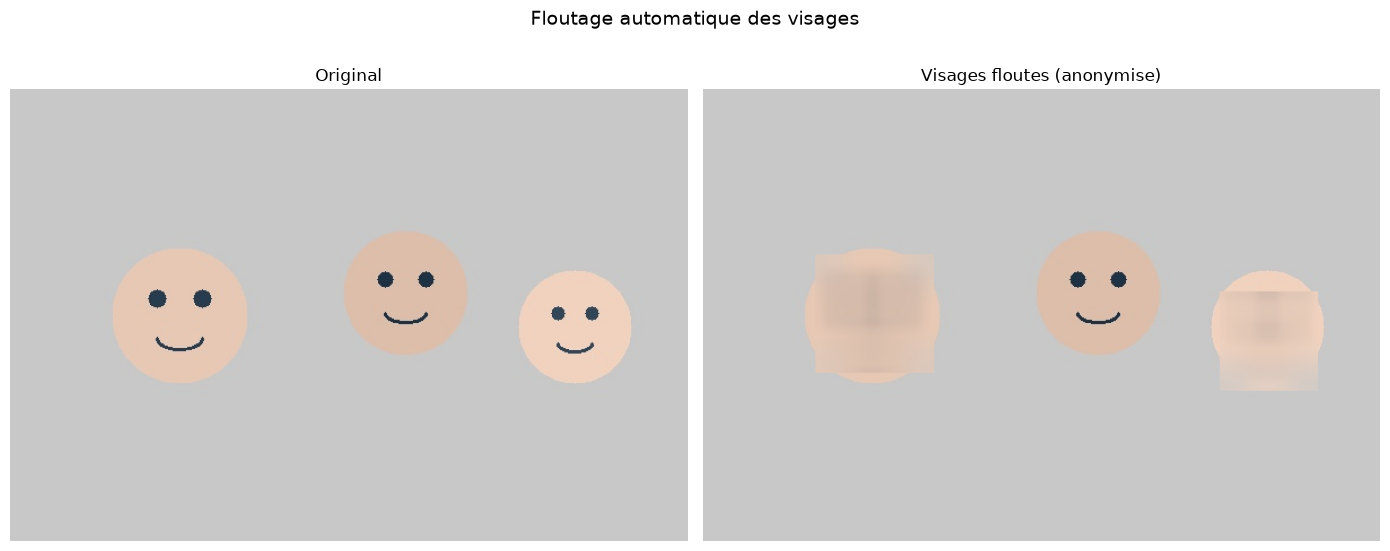

In [28]:
# tester sur notre image people.jpg
_result = blur_faces('people.jpg', blur_strength=51, output_path='people_blurred.jpg')
if _result is not None:
    _fig, _axes = plt.subplots(1, 2, figsize=(14, 6))
    original = cv2.imread('people.jpg')  # afficher avant/apres
    _axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    _axes[0].set_title('Original')
    _axes[0].axis('off')
    _axes[1].imshow(cv2.cvtColor(_result, cv2.COLOR_BGR2RGB))
    _axes[1].set_title('Visages floutes (anonymise)')
    _axes[1].axis('off')
    plt.suptitle('Floutage automatique des visages', fontsize=14)
    plt.tight_layout()
    plt.show()
else:
    print('le floutage a pas marche')

visages detectes: 2
  visage 1 floute: (100,146) -> (205,251)
  visage 2 floute: (458,179) -> (545,267)


visages detectes: 2
  visage 1 floute: (100,146) -> (205,251)
  visage 2 floute: (458,179) -> (545,267)


visages detectes: 2
  visage 1 floute: (100,146) -> (205,251)
  visage 2 floute: (458,179) -> (545,267)


visages detectes: 2
  visage 1 floute: (100,146) -> (205,251)
  visage 2 floute: (458,179) -> (545,267)


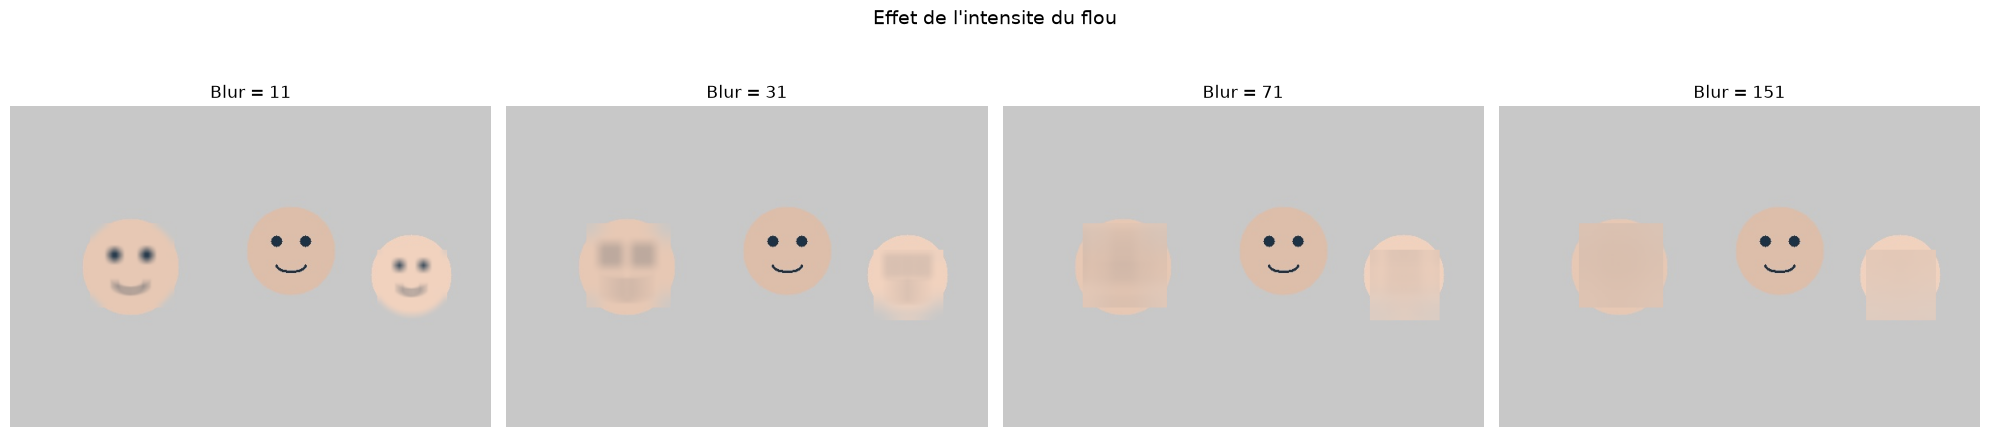

In [29]:
# testons aussi avec differentes intensites de flou pour voir la difference
blur_levels = [11, 31, 71, 151]
_fig, _axes = plt.subplots(1, len(blur_levels), figsize=(20, 5))
for _idx, _blur in enumerate(blur_levels):
    _result = blur_faces('people.jpg', blur_strength=_blur)
    if _result is not None:
        _axes[_idx].imshow(cv2.cvtColor(_result, cv2.COLOR_BGR2RGB))
    _axes[_idx].set_title(f'Blur = {_blur}')
    _axes[_idx].axis('off')
plt.suptitle("Effet de l'intensite du flou", fontsize=14)
plt.tight_layout()
plt.show()

In [30]:
# version video: flouter les visages en temps reel dans une video
# (on utilise notre video de test, sur un vrai PC on utiliserait la webcam)
def blur_faces_video(input_path, output_path, blur_strength=99):
    """
    Applique le floutage des visages sur une video entiere.
    """
    detector = dlib.get_frontal_face_detector()
    cap = cv2.VideoCapture(input_path)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (w, h))
    frame_count = 0
    total_faces = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = detector(gray)
        for face in faces:
            x, y = (max(0, face.left()), max(0, face.top()))
            x2 = min(w, face.left() + face.width())
            y2 = min(h, face.top() + face.height())
            k = blur_strength if blur_strength % 2 == 1 else blur_strength + 1
            frame[y:y2, x:x2] = cv2.GaussianBlur(frame[y:y2, x:x2], (k, k), 30)
            total_faces = total_faces + 1
        out.write(frame)
        frame_count = frame_count + 1
    cap.release()
    out.release()
    print(f'video traitee: {frame_count} frames, {total_faces} visages floutes au total')
    print(f'sauvegardee: {output_path}')
# NB: avec notre video de test synthetique y aura pas de visages a detecter
# mais le code est pret pour des vraies videos
blur_faces_video('test_video.mp4', 'video_anonymisee.mp4')

video traitee: 100 frames, 0 visages floutes au total
sauvegardee: video_anonymisee.mp4


### README du mini-projet

**Objectif**: Detecter automatiquement les visages dans des images ou videos et les flouter pour l'anonymisation (conformite RGPD / vie privee).

**Installation**:
```bash
pip install opencv-python dlib numpy matplotlib
# sous Windows: pip install dlib-bin
```

**Utilisation**:
```python
# pour une image
result = blur_faces("photo.jpg", blur_strength=99, output_path="photo_anonyme.jpg")

# pour une video
blur_faces_video("video.mp4", "video_anonyme.mp4", blur_strength=99)
```

**Parametres**:
- `blur_strength`: intensite du flou (11=leger, 51=moyen, 99=fort, 151=tres fort). Doit etre impair.
- Le detecteur utilise HOG (dlib) qui fonctionne bien sur les visages de face.
- Pour des visages de profil ou inclines, on pourrait passer a un detecteur CNN (`dlib.cnn_face_detection_model_v1()`) mais c'est plus lent.

**Limites**:
- Ne detecte pas les visages tres petits ou tres inclines
- Le flou gaussien est rectangulaire (pas la forme exacte du visage)
- Performance en temps reel depend du nombre de visages et de la resolution

---
## Conclusion

ce que j'ai retenu de ce TP:

1. **OpenCV** est la base pour tout ce qui est manipulation d'images/videos. BGR pas RGB, faut s'en souvenir.

2. **La conversion en gris** simplifie les calculs et est souvent suffisante pour la detection de contours, de visages, etc.

3. **Le flou gaussien** est un pretraitement important avant la detection de contours pour reduire le bruit.

4. **Detectron2 / Mask R-CNN** donne des resultats tres precis avec des masques de segmentation, mais c'est lent.

5. **YOLO** est beaucoup plus rapide et adapte au temps reel. yolov8n-seg donne aussi des masques.

6. **dlib / face_recognition** pour la detection et reconnaissance de visages. Les 68 landmarks sont utiles pour plein d'applications (somnolence, filtres, etc.).

7. **Le EAR** (Eye Aspect Ratio) est une mesure simple mais efficace pour detecter si les yeux sont ouverts ou fermes.

8. Le choix du modele depend toujours du compromis vitesse vs precision.